<a href="https://colab.research.google.com/github/akshu88/Applied-ML-Lab/blob/main/Exp_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1) Import the Libraries**

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# **2) Load the dataset**

In [2]:
train = pd.read_csv('mitbih_train.csv', header = None)
test = pd.read_csv('mitbih_test.csv', header = None)

# **3) Train test split**

In [3]:
# Last column = label, 0 = Normal, 1/2/3/4 = Abnormal
X_train = train.iloc[: ,:-1].values
Y_train = (train.iloc[: , -1] != 0).astype(int).values

X_test = test.iloc[:, :-1].values
Y_test = (test.iloc[:, -1] != 0).astype(int).values

print("Train shape: ", X_train.shape)
print("Test shape: ", X_test.shape)
print("Normal va Abnormal in train: ", np.bincount(Y_train))

Train shape:  (87554, 187)
Test shape:  (21892, 187)
Normal va Abnormal in train:  [72471 15083]


# **4) Plot the data**

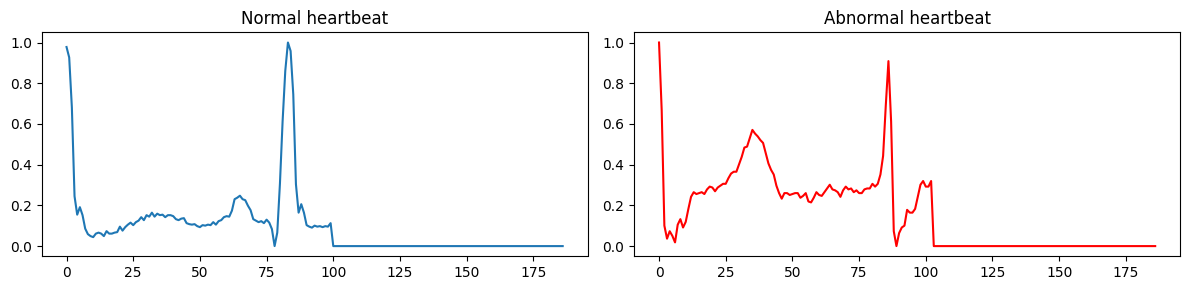

In [4]:
plt.figure(figsize=(12, 3))
plt.subplot(1,2,1)
plt.plot(X_train[np.where(Y_train == 0)[0][0]])
plt.title("Normal heartbeat")
plt.subplot(1,2,2)

plt.plot(X_train[np.where(Y_train == 1)[0][0]], color = 'red')
plt.title("Abnormal heartbeat")
plt.tight_layout()
plt.show()

# **5) Feature Extraction**

In [8]:
def get_features(X):
  features = pd.DataFrame()
  features['mean'] = X.mean(axis=1)
  features['std'] = X.std(axis=1)
  features['min'] = X.min(axis=1)
  features['max'] = X.max(axis=1)
  features['median'] = np.median(X,axis=1)
  features['skewness'] = skew(X,axis=1)
  features['kurtosis'] = kurtosis(X,axis=1)
  features['energy'] = (X**2).sum(axis=1)
  features['peak_pos'] = X.argmax(axis=1)
  features['mean_diff'] = np.abs(np.diff(X, axis=1)).mean(axis=1)
  return features.fillna(0)
X_train = get_features(X_train)
X_test = get_features(X_test)
print("\nExtracted features: ", list(X_train.columns))


Extracted features:  ['mean', 'std', 'min', 'max', 'median', 'skewness', 'kurtosis', 'energy', 'peak_pos', 'mean_diff']


# **5) Define Models**

In [9]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN":                 make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "SVM":                 make_pipeline(StandardScaler(), SVC()),
    "Decision Tree":       DecisionTreeClassifier(random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=100, random_state=42),
}

# **6) Train and Evaluate**

In [15]:
# ---------- 6. TRAIN AND EVALUATE ----------

# NEW: pick 15000 random rows for SVM
svm_idx = np.random.RandomState(42).choice(len(X_train), 15000, replace=False)

results = []
predictions = {}

for name, model in models.items():
    print("Training", name, "...")
    if name == "SVM":
        model.fit(X_train.iloc[svm_idx], Y_train[svm_idx])   # CHANGED
    else:
        model.fit(X_train, Y_train)

    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(Y_test, y_pred),
        "Precision": precision_score(Y_test, y_pred),
        "Recall":    recall_score(Y_test, y_pred),
        "F1-score":  f1_score(Y_test, y_pred),
    })

results_df = pd.DataFrame(results).set_index("Model").round(4)
print("\n===== COMPARISON TABLE =====")
print(results_df)

Training Logistic Regression ...
Training KNN ...
Training SVM ...
Training Decision Tree ...
Training Random Forest ...

===== COMPARISON TABLE =====
                     Accuracy  Precision  Recall  F1-score
Model                                                     
Logistic Regression    0.8726     0.8187  0.3349    0.4754
KNN                    0.9438     0.8803  0.7798    0.8270
SVM                    0.8943     0.9220  0.4226    0.5796
Decision Tree          0.9197     0.7709  0.7597    0.7652
Random Forest          0.9490     0.9219  0.7695    0.8388


# **7) Comparison Graph**

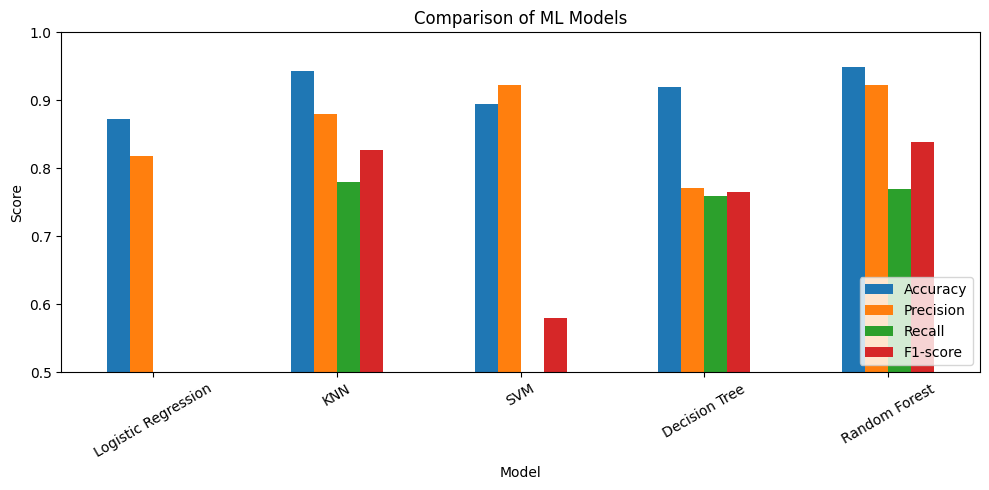

In [16]:
results_df.plot(kind='bar', figsize=(10, 5))
plt.title("Comparison of ML Models")
plt.ylabel("Score")
plt.ylim(0.5, 1.0)
plt.xticks(rotation=30)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# **8) Confusion Matrix**

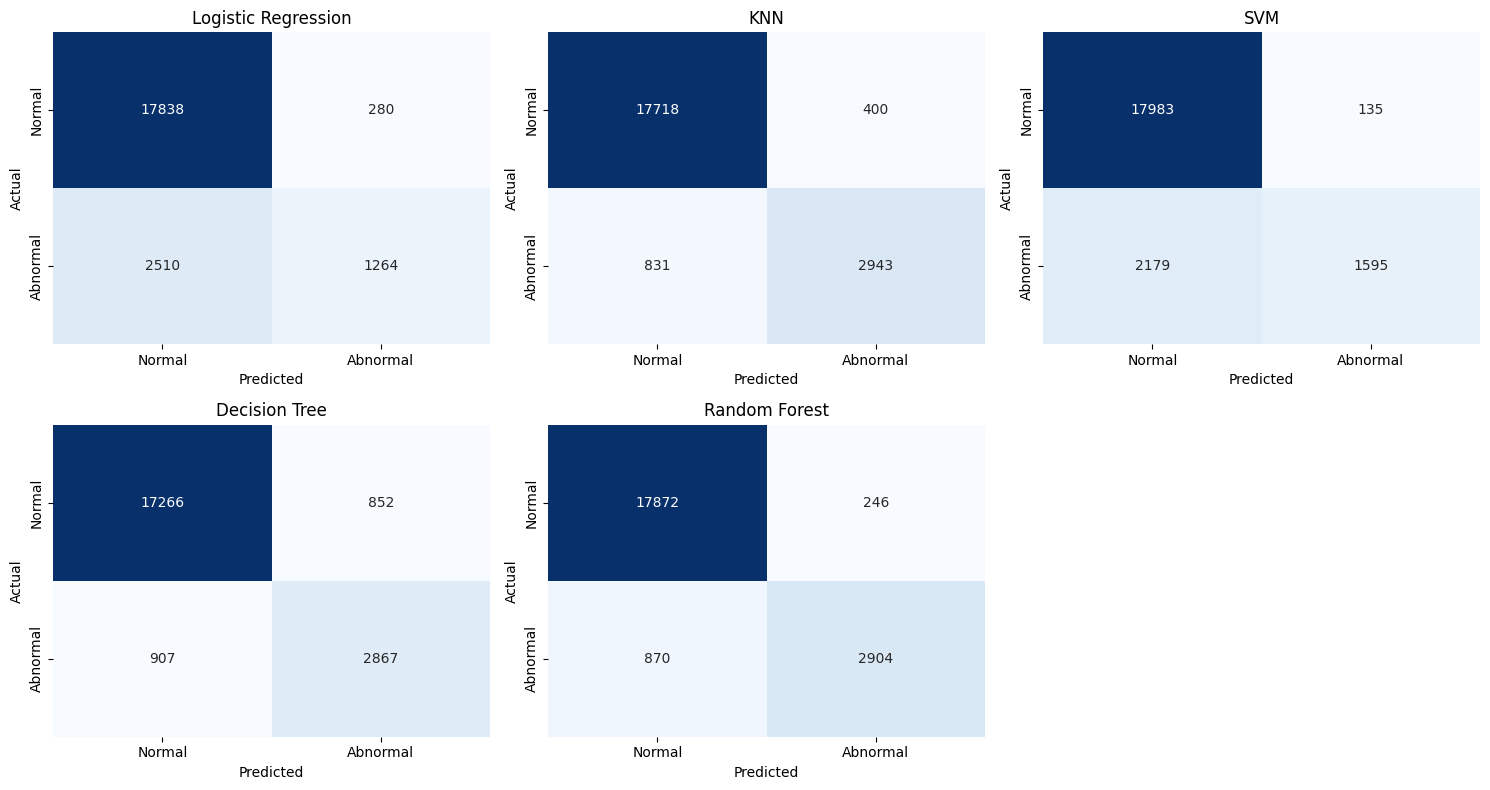

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for i, name in enumerate(predictions):
    cm = confusion_matrix(Y_test, predictions[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[i],
                xticklabels=['Normal', 'Abnormal'],
                yticklabels=['Normal', 'Abnormal'])
    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")
axes[5].axis('off')   # empty 6th box
plt.tight_layout()
plt.show()

# **Conclusion**

In [19]:
best = results_df['F1-score'].idxmax()
print("\nBest model:", best)
print(results_df.loc[best])


Best model: Random Forest
Accuracy     0.9490
Precision    0.9219
Recall       0.7695
F1-score     0.8388
Name: Random Forest, dtype: float64
